In [1]:
#Tree Based model for Emp Attrition
import warnings
warnings.filterwarnings("ignore")

import random
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


SEED = 42

np.random.seed(SEED)
random.seed(SEED)


from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    cross_validate,
    learning_curve
)


from sklearn.feature_selection import (
    SelectFromModel,
    SelectKBest,
    mutual_info_classif,
    RFE,
    f_classif
)

from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE


from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.linear_model import LogisticRegression


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    classification_report,
    brier_score_loss
)


from sklearn.calibration import calibration_curve


from statsmodels.stats.contingency_tables import mcnemar


import shap

import sklearn
import imblearn
import catboost
import xgboost
import lightgbm

print("Random Seed:", SEED)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)
print("CatBoost:", catboost.__version__)
print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)

Random Seed: 42
Scikit-learn: 1.7.2
Imbalanced-learn: 0.14.0
CatBoost: 1.2.10
XGBoost: 3.4.0
LightGBM: 4.6.0


In [3]:
FILE_NAME = "Employee attrition dataset for tree-based models.xlsx"
df = pd.read_excel(FILE_NAME)

print("Dataset shape :", df.shape)

print("\nMISSING VALUES")
missing_values = df.isnull().sum()
if missing_values.sum() == 0:
    print("No missing values found.")
else:
    print(
        missing_values[missing_values > 0]
        .sort_values(ascending=False)
    )
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

print("\n DISTRIBUTION OF ATTRITION Y/N")
if "Attrition" in df.columns:

    target_counts = df["Attrition"].value_counts().sort_index()
    target_percent = (
        df["Attrition"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )

    target_summary = pd.DataFrame({
        "Count": target_counts,
        "Percentage": target_percent.round(2)
    })

    print(target_summary)
display(df.head())

Dataset shape : (1174, 34)

MISSING VALUES
No missing values found.
Number of duplicate rows: 1

 DISTRIBUTION OF ATTRITION Y/N
           Count  Percentage
Attrition                   
0            676       57.58
1            498       42.42


,Attrition,Gender,Age,Maritalstatus,Academic_degree,Years_Experience,Years_experience_lastorganization,Sector,Department,JobTitle,...,Job_Engagement,Distance_to_work,Work_Live_Balance,Physical_Stress,Psychological_Exhaustion,Job_Stability,Health_Issues,Environment_Satisfaction,Job_Satisfaction,Job_Opportunities
0,1,0,1,0.405953,2,0,0,0.359278,0.600378,0.623277,...,1,1,1,2,0,0,1,1,0,1
1,0,0,0,0.447209,2,0,0,0.359278,0.600378,0.623277,...,1,1,1,0,0,1,0,1,1,0
2,0,0,0,0.447209,1,0,0,0.260830,0.229320,0.190450,...,1,0,1,2,1,0,0,1,1,1
3,0,0,0,0.447209,1,0,0,0.260830,0.229320,0.190450,...,1,1,1,2,2,0,0,0,0,0
4,0,0,0,0.447209,1,0,0,0.260830,0.229320,0.190450,...,1,1,1,1,1,0,0,1,0,0


In [4]:
#recronstruct the dept and sector lables as its encoded

SECTOR_MAP = {
    0.26083033629882: 'Education',
    0.35927823:       'Medical',
    0.456738097:      'Financial',
    0.512492902:      'Food',
    0.565186601:      'Other'
}

DEPT_MAP = {
    0.22931995:  'Teaching',
    0.263179389: 'Patient Affairs',
    0.368713041: 'Administration',
    0.464504831: 'Customer Service',
    0.506845858: 'Sales',
    0.555348886: 'Processes',
    0.556473595: 'Other',
    0.600377981: 'Accounting'
}


def map_with_tolerance(series, name_map, col_name, tol=1e-6):
   
    keys = np.array(list(name_map.keys()))
    names = np.array(list(name_map.values()))

    labels = []

    for val in series:

        if pd.isna(val):
            labels.append('Unknown')
            continue

        diffs = np.abs(keys - float(val))
        idx = diffs.argmin()

        if diffs[idx] <= tol:
            labels.append(names[idx])
        else:
            labels.append('Unknown')

    result = pd.Series(labels, index=series.index)

    unknown_vals = series[result == 'Unknown'].unique()

    if len(unknown_vals) > 0:
        raise ValueError(
            f"\n[ERROR] '{col_name}': "
            f"{(result == 'Unknown').sum()} rows could not be matched."
            f"\nUnmatched values: {unknown_vals}"
            f"\nAdd these values to the mapping dictionary."
        )

    return result


df['Sector_Label'] = map_with_tolerance(
    df['Sector'],
    SECTOR_MAP,
    'Sector'
)

df['Dept_Label'] = map_with_tolerance(
    df['Department'],
    DEPT_MAP,
    'Department'
)


print("SECTOR DISTRIBUTION")
print("=" * 60)
print(df['Sector_Label'].value_counts().to_string())

print("\nDEPARTMENT DISTRIBUTION")
print("=" * 60)
print(df['Dept_Label'].value_counts().to_string())

SECTOR DISTRIBUTION
Sector_Label
Other        343
Medical      298
Education    269
Financial    151
Food         113

DEPARTMENT DISTRIBUTION
Dept_Label
Other               219
Administration      190
Teaching            184
Patient Affairs     145
Customer Service    142
Sales               134
Processes            97
Accounting           63


In [4]:
X = df.drop(
    columns=[
        'Attrition',
        'Sector_Label',
        'Dept_Label'
    ]
)

# ---------------------------------------------------------------
# Target variable
# ---------------------------------------------------------------
y = df['Attrition']

# ---------------------------------------------------------------
# Dataset overview
# ---------------------------------------------------------------
print("FEATURE AND TARGET OVERVIEW")
print("=" * 60)

print("Number of observations :", X.shape[0])
print("Number of features     :", X.shape[1])

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nTarget percentage:")
print((y.value_counts(normalize=True)
       .sort_index() * 100).round(2))

# ---------------------------------------------------------------
# Dataset fingerprints
# ---------------------------------------------------------------
def dataframe_hash(data):
    """
    Create a reproducible SHA-256 fingerprint of a DataFrame or
    Series, including its index.
    """
    if isinstance(data, pd.Series):
        hashed_values = pd.util.hash_pandas_object(
            data,
            index=True
        ).values
    else:
        hashed_values = pd.util.hash_pandas_object(
            data,
            index=True
        ).values

    return hashlib.sha256(
        hashed_values.tobytes()
    ).hexdigest()


print("\nDATASET FINGERPRINTS")
print("=" * 60)

print("X :", dataframe_hash(X))
print("y :", dataframe_hash(y))

# ---------------------------------------------------------------
# Store feature names
# ---------------------------------------------------------------
feature_names = X.columns.tolist()

print("\nFEATURE NAMES")
print("=" * 60)

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

FEATURE AND TARGET OVERVIEW
Number of observations : 1174
Number of features     : 33

Target distribution:
Attrition
0    676
1    498
Name: count, dtype: int64

Target percentage:
Attrition
0    57.58
1    42.42
Name: proportion, dtype: float64

DATASET FINGERPRINTS
X : c8be2da8e1f2da368cd1e62361697718784237ea620e8a22e4d48543d7405d52
y : 9cc16b54b836a11a664fc73c04f358198f7f7c3d800448387f38a2f148d1455a

FEATURE NAMES
 1. Gender
 2. Age
 3. Maritalstatus
 4. Academic_degree
 5. Years_Experience
 6. Years_experience_lastorganization
 7. Sector
 8. Department
 9. JobTitle
10. MonthlySalary
11. Allowances
12. MedicalInsurance
13. Bonus
14. OverTime
15. Payment_Overtime
16. Rewards_Wages_Satisfaction
17. Get_Deserved_Promotion
18. Training_programs_During_last_three_years
19. Useful_Training_Programs
20. Business_Travel
21. Job_Support
22. Recognition
23. Emotional_Commitment
24. Job_Engagement
25. Distance_to_work
26. Work_Live_Balance
27. Physical_Stress
28. Psychological_Exhaustion
29. 

In [5]:
# ===============================================================
# CELL 5: FIXED TRAIN-TEST SPLIT
# ===============================================================

# ---------------------------------------------------------------
# Create fixed stratified 80:20 train-test split
# ---------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# ---------------------------------------------------------------
# Align subgroup labels with test observations
# ---------------------------------------------------------------
# train_test_split shuffles the observations.
# Therefore, labels must be recovered using the original index,
# not positional indexing.

sector_test = df.loc[X_test.index, 'Sector_Label'].copy()
dept_test   = df.loc[X_test.index, 'Dept_Label'].copy()


# ---------------------------------------------------------------
# Display split information
# ---------------------------------------------------------------

print("TRAIN-TEST SPLIT")
print("=" * 60)

print("Training observations :", X_train.shape[0])
print("Test observations     :", X_test.shape[0])

print("\nTraining shape :", X_train.shape)
print("Test shape     :", X_test.shape)


# ---------------------------------------------------------------
# Class distribution check
# ---------------------------------------------------------------

print("\nTRAINING TARGET DISTRIBUTION")
print("-" * 60)

train_distribution = pd.DataFrame({
    "Count": y_train.value_counts().sort_index(),
    "Percentage": (
        y_train.value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )
})

print(train_distribution)


print("\nTEST TARGET DISTRIBUTION")
print("-" * 60)

test_distribution = pd.DataFrame({
    "Count": y_test.value_counts().sort_index(),
    "Percentage": (
        y_test.value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )
})

print(test_distribution)


# ---------------------------------------------------------------
# Split fingerprints
# ---------------------------------------------------------------

print("\nSPLIT FINGERPRINTS")
print("=" * 60)

print("X_train :", dataframe_hash(X_train))
print("X_test  :", dataframe_hash(X_test))
print("y_train :", dataframe_hash(y_train))
print("y_test  :", dataframe_hash(y_test))


# ---------------------------------------------------------------
# Verify subgroup labels
# ---------------------------------------------------------------

print("\nSECTOR LABELS IN TEST SET")
print("-" * 60)
print(sorted(sector_test.unique()))

print("\nDEPARTMENT LABELS IN TEST SET")
print("-" * 60)
print(sorted(dept_test.unique()))

TRAIN-TEST SPLIT
Training observations : 939
Test observations     : 235

Training shape : (939, 33)
Test shape     : (235, 33)

TRAINING TARGET DISTRIBUTION
------------------------------------------------------------
           Count  Percentage
Attrition                   
0            541       57.61
1            398       42.39

TEST TARGET DISTRIBUTION
------------------------------------------------------------
           Count  Percentage
Attrition                   
0            135       57.45
1            100       42.55

SPLIT FINGERPRINTS
X_train : b8a9b4f7f65dfe82758150ca50568d7dd9ac22fba2bea3a8463efe2853e4e9f7
X_test  : b562ade9f96d9cb03113baef57e932f420d437cae718f979831ab8ef66db56f5
y_train : 8423828b89c788cb8971472f886905b991f52be75d449135aac71d7adb619ab1
y_test  : 9720b989100775447c2b62fe79fecc80430cce0a6614433cb6f8f4d50a9636be

SECTOR LABELS IN TEST SET
------------------------------------------------------------
[np.str_('Education'), np.str_('Financial'), np.str_('

In [6]:
# ===============================================================
# CELL 6: CROSS-VALIDATION AND EVALUATION METRICS
# ===============================================================

# ---------------------------------------------------------------
# Repeated Stratified 5-Fold Cross-Validation
# ---------------------------------------------------------------
# 5 folds × 3 repeats = 15 validation evaluations per model
#
# The CV is performed ONLY on X_train and y_train.
# The independent X_test and y_test remain untouched.

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=SEED
)

# ---------------------------------------------------------------
# Evaluation metrics
# ---------------------------------------------------------------
# ROC-AUC is the primary model-selection metric.
# Other metrics provide complementary performance information.

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# ---------------------------------------------------------------
# Display configuration
# ---------------------------------------------------------------

print("CROSS-VALIDATION CONFIGURATION")
print("=" * 65)

print("CV Method       : Repeated Stratified K-Fold")
print("Number of Folds :", 5)
print("Number of Repeats:", 3)
print("Total CV Runs   :", 5 * 3)
print("Random Seed     :", SEED)

print("\nMODEL SELECTION METRICS")
print("-" * 65)

for metric in scoring.keys():
    print(f"- {metric}")

print("\nPRIMARY MODEL-SELECTION METRIC: ROC-AUC")
print("\n[OK] Cross-validation configuration is fixed.")
print("[OK] The independent test set remains untouched.")

CROSS-VALIDATION CONFIGURATION
CV Method       : Repeated Stratified K-Fold
Number of Folds : 5
Number of Repeats: 3
Total CV Runs   : 15
Random Seed     : 42

MODEL SELECTION METRICS
-----------------------------------------------------------------
- accuracy
- precision
- recall
- f1
- roc_auc

PRIMARY MODEL-SELECTION METRIC: ROC-AUC

[OK] Cross-validation configuration is fixed.
[OK] The independent test set remains untouched.


In [7]:
# ===============================================================
# CELL 7: TREE-BASED MODEL DEFINITIONS
# ===============================================================

# ---------------------------------------------------------------
# Individual Tree-Based Models
# ---------------------------------------------------------------

dt = DecisionTreeClassifier(
    max_depth=6,
    random_state=SEED
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    random_state=SEED,
    n_jobs=-1
)

et = ExtraTreesClassifier(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1
)

gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    random_state=SEED
)

ada = AdaBoostClassifier(
    n_estimators=200,
    learning_rate=0.05,
    random_state=SEED
)

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="logloss",
    random_state=SEED
)

lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    random_state=SEED
)

cat = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    verbose=0,
    random_state=SEED
)

# ---------------------------------------------------------------
# Ensemble Models
# ---------------------------------------------------------------

voting = VotingClassifier(
    estimators=[
        ("rf", rf),
        ("et", et),
        ("xgb", xgb),
        ("cat", cat)
    ],
    voting="soft"
)

stacking = StackingClassifier(
    estimators=[
        ("rf", rf),
        ("et", et),
        ("xgb", xgb),
        ("cat", cat)
    ],
    final_estimator=LogisticRegression(),
    cv=5,
    n_jobs=-1
)

# ---------------------------------------------------------------
# Model Dictionary
# ---------------------------------------------------------------

tree_models = {
    "Decision Tree": dt,
    "Random Forest": rf,
    "Extra Trees": et,
    "Gradient Boosting": gb,
    "AdaBoost": ada,
    "XGBoost": xgb,
    "LightGBM": lgbm,
    "CatBoost": cat,
    "Voting Ensemble": voting,
    "Stacking Ensemble": stacking
}

print("TREE-BASED MODELS")
print("=" * 60)

for i, model_name in enumerate(tree_models.keys(), start=1):
    print(f"{i}. {model_name}")

print(f"\nTotal models defined: {len(tree_models)}")
print("\n[OK] Tree-based models are ready.")

TREE-BASED MODELS
1. Decision Tree
2. Random Forest
3. Extra Trees
4. Gradient Boosting
5. AdaBoost
6. XGBoost
7. LightGBM
8. CatBoost
9. Voting Ensemble
10. Stacking Ensemble

Total models defined: 10

[OK] Tree-based models are ready.


In [8]:
# ===============================================================
# CELL 8: FEATURE SELECTION METHODS
# ===============================================================

# Number of features available in the training data
n_features = X_train.shape[1]

# ---------------------------------------------------------------
# Feature Selection Configurations
# ---------------------------------------------------------------

feature_selectors = {

    # Use all available features
    "ALL": "passthrough",

    # Top features based on ANOVA F-test
    "SelectKBest": SelectKBest(
        score_func=f_classif,
        k=min(20, n_features)
    ),

    # Top features based on mutual information
    "MutualInformation": SelectKBest(
        score_func=mutual_info_classif,
        k=min(15, n_features)
    ),

    # Recursive Feature Elimination
    "RFE": RFE(
        estimator=RandomForestClassifier(
            n_estimators=100,
            random_state=SEED,
            n_jobs=-1
        ),
        n_features_to_select=min(15, n_features)
    ),

    # Embedded feature selection using Random Forest
    "RF_Embedded": SelectFromModel(
        estimator=RandomForestClassifier(
            n_estimators=200,
            random_state=SEED,
            n_jobs=-1
        )
    )
}


# ---------------------------------------------------------------
# Display Configuration
# ---------------------------------------------------------------

print("FEATURE SELECTION CONFIGURATION")
print("=" * 65)

print("Total available features:", n_features)

print("\nFeature selection methods:")

for i, name in enumerate(feature_selectors.keys(), start=1):
    print(f"{i}. {name}")

print("\nConfiguration details:")
print("- ALL                : All 33 features")
print(f"- SelectKBest        : Top {min(20, n_features)} features")
print(f"- MutualInformation  : Top {min(15, n_features)} features")
print(f"- RFE                : Top {min(15, n_features)} features")
print("- RF_Embedded        : Features selected automatically")

print("\n[OK] Feature selection configurations are ready.")

FEATURE SELECTION CONFIGURATION
Total available features: 33

Feature selection methods:
1. ALL
2. SelectKBest
3. MutualInformation
4. RFE
5. RF_Embedded

Configuration details:
- ALL                : All 33 features
- SelectKBest        : Top 20 features
- MutualInformation  : Top 15 features
- RFE                : Top 15 features
- RF_Embedded        : Features selected automatically

[OK] Feature selection configurations are ready.


In [9]:
# ===============================================================
# CELL 9: LEAKAGE-SAFE PIPELINE
# ===============================================================
#
# Pipeline order:
#
# Training fold
#      ↓
# Feature Selection
#      ↓
# SMOTE
#      ↓
# Model
#
# During cross-validation, SMOTE and feature selection are applied
# only to the training portion of each fold.
# ===============================================================

def make_tree_pipeline(model, selector):
    
    pipeline = ImbPipeline(
        steps=[
            # Feature selection is performed using only
            # the original training observations
            ("feature_selection", selector),
            
            # SMOTE is applied after feature selection
            # and only within the training fold
            ("smote", SMOTE(
                random_state=SEED
            )),
            
            # Classification model
            ("model", model)
        ]
    )
    
    return pipeline

# ---------------------------------------------------------------
# Pipeline verification
# ---------------------------------------------------------------

print("TREE MODEL PIPELINE")
print("=" * 65)

print("Step 1 : Feature Selection")
print("Step 2 : SMOTE ")
print("Step 3 : Classification Model")

print("\n[OK] Leakage-safe pipeline function is ready.")

TREE MODEL PIPELINE
Step 1 : Feature Selection
Step 2 : SMOTE 
Step 3 : Classification Model

[OK] Leakage-safe pipeline function is ready.


In [10]:
# ===============================================================
# CELL 10: REPEATED CROSS-VALIDATION — TREE MODELS
# ===============================================================

results = []

print("\nRunning Tree Model Feature Selection Comparison...")
print("=" * 70)

# ---------------------------------------------------------------
# Evaluate every feature-selection and model combination
# ---------------------------------------------------------------

for fs_name, selector in feature_selectors.items():

    print(f"\nFeature Selection: {fs_name}")

    for model_name, model in tree_models.items():

        print(f"  Running: {model_name}")

        pipe = make_tree_pipeline(
            model=model,
            selector=selector
        )

        scores = cross_validate(
            estimator=pipe,
            X=X_train,
            y=y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            error_score="raise"
        )

        # -------------------------------------------------------
        # Store Mean and Standard Deviation
        # -------------------------------------------------------

        results.append({

            "Feature_Set": fs_name,
            "Model": model_name,

            "CV Accuracy Mean":
                scores["test_accuracy"].mean(),

            "CV Accuracy SD":
                scores["test_accuracy"].std(ddof=1),

            "CV Precision Mean":
                scores["test_precision"].mean(),

            "CV Precision SD":
                scores["test_precision"].std(ddof=1),

            "CV Recall Mean":
                scores["test_recall"].mean(),

            "CV Recall SD":
                scores["test_recall"].std(ddof=1),

            "CV F1 Mean":
                scores["test_f1"].mean(),

            "CV F1 SD":
                scores["test_f1"].std(ddof=1),

            "CV ROC_AUC Mean":
                scores["test_roc_auc"].mean(),

            "CV ROC_AUC SD":
                scores["test_roc_auc"].std(ddof=1)
        })


# ===============================================================
# CONVERT RESULTS TO DATAFRAME
# ===============================================================

results_df = pd.DataFrame(results)


# ===============================================================
# CREATE MEAN ± SD DISPLAY COLUMNS
# ===============================================================

results_df["CV Accuracy"] = (
    results_df["CV Accuracy Mean"].map(lambda x: f"{x:.4f}")
    + " ± "
    + results_df["CV Accuracy SD"].map(lambda x: f"{x:.4f}")
)

results_df["CV Precision"] = (
    results_df["CV Precision Mean"].map(lambda x: f"{x:.4f}")
    + " ± "
    + results_df["CV Precision SD"].map(lambda x: f"{x:.4f}")
)

results_df["CV Recall"] = (
    results_df["CV Recall Mean"].map(lambda x: f"{x:.4f}")
    + " ± "
    + results_df["CV Recall SD"].map(lambda x: f"{x:.4f}")
)

results_df["CV F1"] = (
    results_df["CV F1 Mean"].map(lambda x: f"{x:.4f}")
    + " ± "
    + results_df["CV F1 SD"].map(lambda x: f"{x:.4f}")
)

results_df["CV ROC_AUC"] = (
    results_df["CV ROC_AUC Mean"].map(lambda x: f"{x:.4f}")
    + " ± "
    + results_df["CV ROC_AUC SD"].map(lambda x: f"{x:.4f}")
)


# ===============================================================
# SORT RESULTS
# ===============================================================
# Primary criterion   : Mean ROC-AUC
# Secondary criterion : Mean F1-score

results_df = results_df.sort_values(
    by=[
        "CV ROC_AUC Mean",
        "CV F1 Mean"
    ],
    ascending=False
).reset_index(drop=True)


# ===============================================================
# DISPLAY RESULTS
# ===============================================================

display_columns = [
    "Feature_Set",
    "Model",
    "CV Accuracy",
    "CV Precision",
    "CV Recall",
    "CV F1",
    "CV ROC_AUC"
]

print("\n" + "=" * 110)
print("FINAL TREE MODEL COMPARISON — REPEATED CV (MEAN ± SD)")
print("=" * 110)

print(
    results_df[display_columns].to_string(
        index=False
    )
)


# ===============================================================
# DISPLAY TOP 10 CONFIGURATIONS
# ===============================================================

print("\n" + "=" * 110)
print("TOP 10 CONFIGURATIONS BY MEAN CV ROC-AUC")
print("=" * 110)

print(
    results_df[display_columns]
    .head(10)
    .to_string(index=False)
)


Running Tree Model Feature Selection Comparison...

Feature Selection: ALL
  Running: Decision Tree
  Running: Random Forest
  Running: Extra Trees
  Running: Gradient Boosting
  Running: AdaBoost
  Running: XGBoost
  Running: LightGBM
  Running: CatBoost
  Running: Voting Ensemble
  Running: Stacking Ensemble

Feature Selection: SelectKBest
  Running: Decision Tree
  Running: Random Forest
  Running: Extra Trees
  Running: Gradient Boosting
  Running: AdaBoost
  Running: XGBoost
  Running: LightGBM
  Running: CatBoost
  Running: Voting Ensemble
  Running: Stacking Ensemble

Feature Selection: MutualInformation
  Running: Decision Tree
  Running: Random Forest
  Running: Extra Trees
  Running: Gradient Boosting
  Running: AdaBoost
  Running: XGBoost
  Running: LightGBM
  Running: CatBoost
  Running: Voting Ensemble
  Running: Stacking Ensemble

Feature Selection: RFE
  Running: Decision Tree
  Running: Random Forest
  Running: Extra Trees
  Running: Gradient Boosting
  Running: AdaBoo

In [11]:
# ===============================================================
# CELL 11: FREEZE BEST TREE MODEL CONFIGURATION
# ===============================================================

# ---------------------------------------------------------------
# Best configuration selected using repeated CV
# Primary criterion: Mean CV ROC-AUC
# ---------------------------------------------------------------

best_tree_model_name = "CatBoost"
best_tree_feature_set = "ALL"

# Retrieve model and selector
best_tree_model = tree_models[best_tree_model_name]
best_tree_selector = feature_selectors[best_tree_feature_set]

# Create final pipeline
best_tree_pipeline = make_tree_pipeline(
    model=best_tree_model,
    selector=best_tree_selector
)

# ---------------------------------------------------------------
# Display selected configuration
# ---------------------------------------------------------------

print("BEST TREE MODEL CONFIGURATION")
print("=" * 65)

print("Feature Set :", best_tree_feature_set)
print("Model       :", best_tree_model_name)

print("\nCV ROC-AUC : 0.9132 ± 0.0132")

print("\nPipeline:")
print("SMOTE → ALL Features → CatBoost")

print("\n[OK] Best tree-based configuration has been frozen.")

BEST TREE MODEL CONFIGURATION
Feature Set : ALL
Model       : CatBoost

CV ROC-AUC : 0.9132 ± 0.0132

Pipeline:
SMOTE → ALL Features → CatBoost

[OK] Best tree-based configuration has been frozen.


LEARNING CURVE RESULTS
 Training Samples  Train ROC-AUC Mean  Train ROC-AUC SD  Validation ROC-AUC Mean  Validation ROC-AUC SD
               75                 1.0          0.000000                 0.806121               0.050121
              150                 1.0          0.000000                 0.858666               0.032906
              225                 1.0          0.000000                 0.883020               0.019599
              300                 1.0          0.000000                 0.887011               0.017947
              375                 1.0          0.000000                 0.895078               0.014804
              450                 1.0          0.000000                 0.896463               0.013080
              525                 1.0          0.000000                 0.903269               0.011937
              600                 1.0          0.000000                 0.907757               0.013716
              675                 1.0    

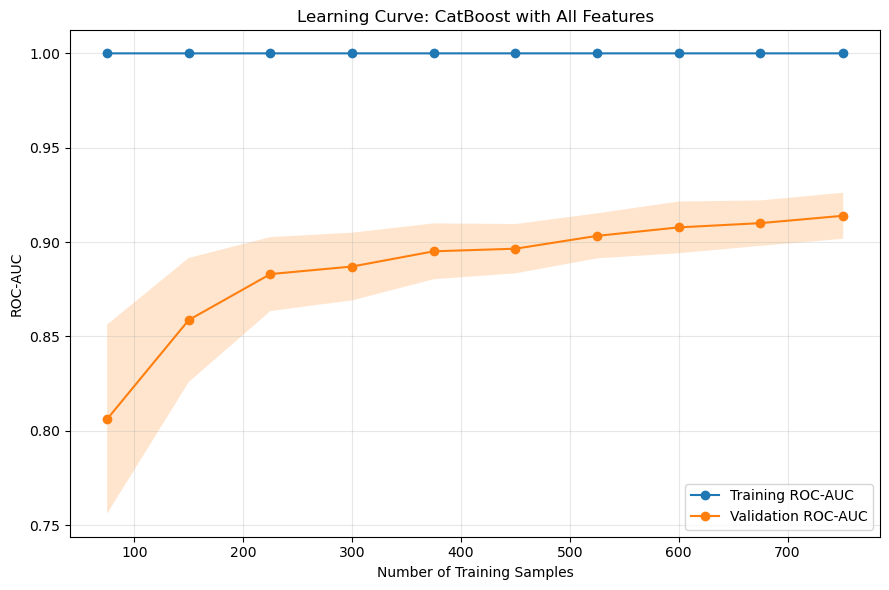

LEARNING CURVE SUMMARY
Final Training ROC-AUC   : 1.0000 ± 0.0000
Final CV ROC-AUC         : 0.9139 ± 0.0122

Training–Validation Gap  : 0.0861


In [12]:
# ===============================================================
# CELL 12: LEARNING CURVE — BEST TREE MODEL
# ===============================================================

# ---------------------------------------------------------------
# Training set sizes
# ---------------------------------------------------------------
train_sizes = np.linspace(
    0.1,
    1.0,
    10
)

# ---------------------------------------------------------------
# Generate learning curve
# ---------------------------------------------------------------

train_sizes_abs, train_scores, validation_scores = learning_curve(
    
    estimator=best_tree_pipeline,
    
    X=X_train,
    y=y_train,
    
    train_sizes=train_sizes,
    
    cv=cv,
    
    scoring="roc_auc",
    
    n_jobs=-1,
    
    shuffle=True,
    
    random_state=SEED
)


# ---------------------------------------------------------------
# Calculate Mean and Standard Deviation
# ---------------------------------------------------------------

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)


# ---------------------------------------------------------------
# Display numerical results
# ---------------------------------------------------------------

learning_curve_results = pd.DataFrame({
    
    "Training Samples": train_sizes_abs,
    
    "Train ROC-AUC Mean": train_mean,
    
    "Train ROC-AUC SD": train_std,
    
    "Validation ROC-AUC Mean": validation_mean,
    
    "Validation ROC-AUC SD": validation_std
})

print("LEARNING CURVE RESULTS")
print("=" * 80)

print(
    learning_curve_results.to_string(
        index=False
    )
)


# ---------------------------------------------------------------
# Plot Learning Curve
# ---------------------------------------------------------------

plt.figure(figsize=(9, 6))

# Training performance
plt.plot(
    train_sizes_abs,
    train_mean,
    marker="o",
    label="Training ROC-AUC"
)

plt.fill_between(
    train_sizes_abs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)

# Validation performance
plt.plot(
    train_sizes_abs,
    validation_mean,
    marker="o",
    label="Validation ROC-AUC"
)

plt.fill_between(
    train_sizes_abs,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.2
)

plt.xlabel("Number of Training Samples")
plt.ylabel("ROC-AUC")

plt.title(
    "Learning Curve: CatBoost with All Features"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "LearnCurve.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
# ===============================================================
# FINAL LEARNING CURVE SUMMARY
# ===============================================================

print("LEARNING CURVE SUMMARY")
print("=" * 65)

print(
    f"Final Training ROC-AUC   : "
    f"{train_mean[-1]:.4f} ± {train_std[-1]:.4f}"
)

print(
    f"Final CV ROC-AUC         : "
    f"{validation_mean[-1]:.4f} ± "
    f"{validation_std[-1]:.4f}"
)

print(
    f"\nTraining–Validation Gap  : "
    f"{train_mean[-1] - validation_mean[-1]:.4f}")

In [13]:
best_result = results_df.iloc[0]

best_tree_feature_set = best_result["Feature_Set"]
best_tree_model_name  = best_result["Model"]



best_tree_model = tree_models[
    best_tree_model_name
]

best_tree_selector = feature_selectors[
    best_tree_feature_set
]



best_tree_pipeline = make_tree_pipeline(
    model=best_tree_model,
    selector=best_tree_selector
)
=

print("FINAL MODEL TRAINING")
print("=" * 65)

print("Selected Feature Set :", best_tree_feature_set)
print("Selected Model       :", best_tree_model_name)

best_tree_pipeline.fit(
    X_train,
    y_train
)

print(
    f"\n[OK] Final {best_tree_model_name} pipeline "
    "trained on all training data."
)

y_prob_tree = best_tree_pipeline.predict_proba(X_test)[:, 1]


operating_threshold = 0.50

y_pred_tree = (y_prob_tree >= operating_threshold).astype(int)

print("\nOperating Threshold:", operating_threshold)


# ===============================================================
# OVERALL TEST PERFORMANCE
# ===============================================================

tree_test_results = {

    "Model":
        best_tree_model_name,

    "Feature Set":
        best_tree_feature_set,

    "Accuracy":
        accuracy_score(y_test, y_pred_tree),

    "Precision":
        precision_score(y_test, y_pred_tree),

    "Recall":
        recall_score(y_test, y_pred_tree),

    "F1 Score":
        f1_score(y_test, y_pred_tree),

    "ROC AUC":
        roc_auc_score(y_test, y_prob_tree),

    "Brier Score":
        brier_score_loss(y_test, y_prob_tree)
}


print("\n" + "=" * 65)

print(
    f"INDEPENDENT TEST PERFORMANCE — "
    f"{best_tree_model_name.upper()}"
)

print("=" * 65)

for metric, value in tree_test_results.items():

    if metric in ["Model", "Feature Set"]:
        print(f"{metric:<15}: {value}")
    else:
        print(f"{metric:<15}: {value:.4f}")


tree_confusion_matrix = confusion_matrix(
    y_test,
    y_pred_tree
)

print("\nCONFUSION MATRIX")
print("-" * 65)

print(tree_confusion_matrix)

tree_classification_report = classification_report(
    y_test,
    y_pred_tree,
    digits=4
)

print("\nCLASSIFICATION REPORT")
print("-" * 65)

print(tree_classification_report)

FINAL MODEL TRAINING
Selected Feature Set : ALL
Selected Model       : CatBoost

[OK] Final CatBoost pipeline trained on all training data.

Operating Threshold: 0.5

INDEPENDENT TEST PERFORMANCE — CATBOOST
Model          : CatBoost
Feature Set    : ALL
Accuracy       : 0.8128
Precision      : 0.7857
Recall         : 0.7700
F1 Score       : 0.7778
ROC AUC        : 0.8864
Brier Score    : 0.1325

CONFUSION MATRIX
-----------------------------------------------------------------
[[114  21]
 [ 23  77]]

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.8321    0.8444    0.8382       135
           1     0.7857    0.7700    0.7778       100

    accuracy                         0.8128       235
   macro avg     0.8089    0.8072    0.8080       235
weighted avg     0.8124    0.8128    0.8125       235



In [14]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)


N_BOOTSTRAPS = 5000
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

y_true = np.asarray(y_test)
y_pred_arr = np.asarray(y_pred_tree)
y_prob_arr = np.asarray(y_prob_tree)

n_samples = len(y_true)


bootstrap_results_tree = {
    "Accuracy": [],
    "Precision": [],
    "Recall": [],
    "F1 Score": [],
    "ROC AUC": [],
    "Brier Score": []
}


for _ in range(N_BOOTSTRAPS):

    # Sample test observations with replacement
    indices = rng.integers(
        low=0,
        high=n_samples,
        size=n_samples
    )

    y_true_boot = y_true[indices]
    y_pred_boot = y_pred_arr[indices]
    y_prob_boot = y_prob_arr[indices]


    # Accuracy
    bootstrap_results_tree["Accuracy"].append(
        accuracy_score(y_true_boot, y_pred_boot)
    )


    # Precision
    bootstrap_results_tree["Precision"].append(
        precision_score(
            y_true_boot,
            y_pred_boot,
            zero_division=0
        )
    )


    # Recall
    bootstrap_results_tree["Recall"].append(
        recall_score(
            y_true_boot,
            y_pred_boot,
            zero_division=0
        )
    )


    # F1-score
    bootstrap_results_tree["F1 Score"].append(
        f1_score(
            y_true_boot,
            y_pred_boot,
            zero_division=0
        )
    )


    # ROC-AUC
    # ROC-AUC requires both classes to be present
    if len(np.unique(y_true_boot)) == 2:

        bootstrap_results_tree["ROC AUC"].append(
            roc_auc_score(
                y_true_boot,
                y_prob_boot
            )
        )


    # Brier Score
    bootstrap_results_tree["Brier Score"].append(
        brier_score_loss(
            y_true_boot,
            y_prob_boot
        )
    )


ci_results_tree = []

for metric, values in bootstrap_results_tree.items():

    values = np.asarray(values)

    lower_ci = np.percentile(values, 2.5)
    upper_ci = np.percentile(values, 97.5)


    # Original test-set estimate
    if metric == "Accuracy":

        point_estimate = accuracy_score(
            y_true,
            y_pred_arr
        )

    elif metric == "Precision":

        point_estimate = precision_score(
            y_true,
            y_pred_arr,
            zero_division=0
        )

    elif metric == "Recall":

        point_estimate = recall_score(
            y_true,
            y_pred_arr,
            zero_division=0
        )

    elif metric == "F1 Score":

        point_estimate = f1_score(
            y_true,
            y_pred_arr,
            zero_division=0
        )

    elif metric == "ROC AUC":

        point_estimate = roc_auc_score(
            y_true,
            y_prob_arr
        )

    elif metric == "Brier Score":

        point_estimate = brier_score_loss(
            y_true,
            y_prob_arr
        )


    ci_results_tree.append({

        "Metric": metric,

        "Estimate": point_estimate,

        "95% CI Lower": lower_ci,

        "95% CI Upper": upper_ci,

        "95% CI":
            f"[{lower_ci:.4f}, {upper_ci:.4f}]"

    })

tree_ci_results = pd.DataFrame(
    ci_results_tree
)


print(
    "\nBOOTSTRAP 95% CONFIDENCE INTERVALS — "
    "FINAL TREE MODEL"
)

print("=" * 75)

print(
    tree_ci_results.to_string(
        index=False
    )
)


BOOTSTRAP 95% CONFIDENCE INTERVALS — FINAL TREE MODEL
     Metric  Estimate  95% CI Lower  95% CI Upper           95% CI
   Accuracy  0.812766      0.761702      0.859574 [0.7617, 0.8596]
  Precision  0.785714      0.701149      0.863158 [0.7011, 0.8632]
     Recall  0.770000      0.683673      0.848843 [0.6837, 0.8488]
   F1 Score  0.777778      0.710383      0.835821 [0.7104, 0.8358]
    ROC AUC  0.886444      0.841450      0.926522 [0.8415, 0.9265]
Brier Score  0.132503      0.104399      0.163326 [0.1044, 0.1633]


In [18]:
import pandas as pd
import numpy as np

lr_predictions = pd.read_csv(
    "non_tree_test_predictions.csv"
)

print("[OK] Logistic Regression prediction file loaded successfully.")
print("Shape:", lr_predictions.shape)

print("\nColumns:")
print(lr_predictions.columns.tolist())

display(lr_predictions.head())

[OK] Logistic Regression prediction file loaded successfully.
Shape: (235, 3)

Columns:
['Actual', 'LR_Prediction', 'LR_Probability']


,Actual,LR_Prediction,LR_Probability
0,0,0,0.004496
1,1,0,0.044709
2,0,0,0.418621
3,0,0,0.095509
4,0,0,0.009144


In [19]:
tree_actual = np.asarray(y_test)
lr_actual = lr_predictions["Actual"].to_numpy()

if np.array_equal(tree_actual, lr_actual):

    print(
        "[OK] Test observations are perfectly aligned."
    )

else:

    raise ValueError(
        "ERROR: The test observations are not aligned. "
        "Do not run McNemar's test until this is corrected."
    )

[OK] Test observations are perfectly aligned.


In [36]:
import numpy as np
import pandas as pd



tree_actual = np.asarray(y_test)


tree_results = pd.DataFrame({

    "Actual": tree_actual,

    "Predicted": np.asarray(y_pred_arr),

    "Predicted_Probability": np.asarray(y_prob_arr)

})

tree_results.to_csv(
    "final_tree_model_predictions.csv",
    index=False
)

print(
    "[OK] Tree model predictions saved successfully."
)

print("\nFirst five records:")
print(tree_results.head())

[OK] Tree model predictions saved successfully.

First five records:
   Actual  Predicted  Predicted_Probability
0       0          0               0.003416
1       1          0               0.005138
2       0          1               0.603871
3       0          0               0.121418
4       0          0               0.000958


In [21]:
import numpy as np
import pandas as pd

from statsmodels.stats.contingency_tables import mcnemar



y_true = np.asarray(y_test)

catboost_pred = np.asarray(y_pred_tree)

logistic_pred = lr_predictions["LR_Prediction"].to_numpy()


catboost_correct = (
    catboost_pred == y_true
)

logistic_correct = (
    logistic_pred == y_true
)


n00 = np.sum(
    (~catboost_correct) &
    (~logistic_correct)
)

n01 = np.sum(
    (~catboost_correct) &
    logistic_correct
)

n10 = np.sum(
    catboost_correct &
    (~logistic_correct)
)

n11 = np.sum(
    catboost_correct &
    logistic_correct
)


mcnemar_table = np.array([
    [n00, n01],
    [n10, n11]
])



mcnemar_table_df = pd.DataFrame(

    mcnemar_table,

    index=[
        "CatBoost Incorrect",
        "CatBoost Correct"
    ],

    columns=[
        "Logistic Regression Incorrect",
        "Logistic Regression Correct"
    ]
)


print(
    "\nMCNEMAR CONTINGENCY TABLE"
)

print("=" * 65)

print(
    mcnemar_table_df
)


result = mcnemar(
    mcnemar_table,
    exact=True,
    correction=False
)


print(
    "\nMCNEMAR'S TEST RESULTS"
)

print("=" * 65)

print(
    f"Statistic : {result.statistic:.4f}"
)

print(
    f"P-value   : {result.pvalue:.6f}"
)

alpha = 0.05

print("\nINTERPRETATION")
print("-" * 65)

if result.pvalue < alpha:

    print(
        "The difference in classification performance "
        "between CatBoost and Logistic Regression is "
        "statistically significant at α = 0.05."
    )

else:

    print(
        "No statistically significant difference in "
        "classification performance between CatBoost and "
        "Logistic Regression was detected at α = 0.05."
    )



mcnemar_results = pd.DataFrame({

    "Comparison": [
        "CatBoost vs Logistic Regression"
    ],

    "CatBoost Correct / LR Incorrect": [
        n10
    ],

    "CatBoost Incorrect / LR Correct": [
        n01
    ],

    "Test": [
        "Exact McNemar"
    ],

    "P-value": [
        result.pvalue
    ]

})


print(
    "\nSUMMARY"
)

print("=" * 65)

print(
    mcnemar_results.to_string(
        index=False
    )
)


MCNEMAR CONTINGENCY TABLE
                    Logistic Regression Incorrect  Logistic Regression Correct
CatBoost Incorrect                             35                            9
CatBoost Correct                               16                          175

MCNEMAR'S TEST RESULTS
Statistic : 9.0000
P-value   : 0.229523

INTERPRETATION
-----------------------------------------------------------------
No statistically significant difference in classification performance between CatBoost and Logistic Regression was detected at α = 0.05.

SUMMARY
                     Comparison  CatBoost Correct / LR Incorrect  CatBoost Incorrect / LR Correct          Test  P-value
CatBoost vs Logistic Regression                               16                                9 Exact McNemar 0.229523


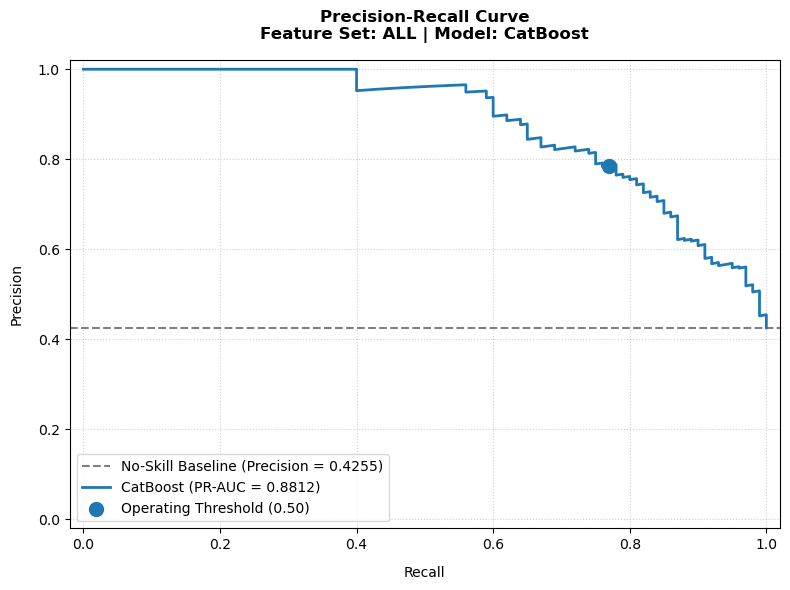

PRECISION-RECALL CURVE SUMMARY
Model              : CatBoost
Feature Set        : ALL
PR-AUC             : 0.8812
Operating Threshold: 0.50
Precision at Threshold: 0.7857
Recall at Threshold   : 0.7700


In [22]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    auc,
    precision_score,
    recall_score
)

precisions, recalls, thresholds = precision_recall_curve(
    y_test,
    y_prob_tree
)

# Calculate PR-AUC
pr_auc = auc(
    recalls,
    precisions
)


no_skill_baseline = np.mean(
    np.asarray(y_test) == 1
)


threshold_for_plot = operating_threshold

y_pred_at_threshold = (
    y_prob_tree >= threshold_for_plot
).astype(int)

precision_at_threshold = precision_score(
    y_test,
    y_pred_at_threshold,
    zero_division=0
)

recall_at_threshold = recall_score(
    y_test,
    y_pred_at_threshold,
    zero_division=0
)


plt.figure(
    figsize=(8, 6),
    dpi=100
)


plt.axhline(
    y=no_skill_baseline,
    linestyle="--",
    color="gray",
    label=(
        f"No-Skill Baseline "
        f"(Precision = {no_skill_baseline:.4f})"
    )
)

plt.plot(
    recalls,
    precisions,
    lw=2,
    label=(
        f"{best_tree_model_name} "
        f"(PR-AUC = {pr_auc:.4f})"
    )
)


plt.scatter(
    recall_at_threshold,
    precision_at_threshold,
    s=100,
    zorder=5,
    label=(
        f"Operating Threshold "
        f"({threshold_for_plot:.2f})"
    )
)

plt.title(
    f"Precision-Recall Curve\n"
    f"Feature Set: {best_tree_feature_set} | "
    f"Model: {best_tree_model_name}",
    fontsize=12,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Recall",
    fontsize=10,
    labelpad=10
)

plt.ylabel(
    "Precision",
    fontsize=10,
    labelpad=10
)

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])

plt.grid(
    True,
    linestyle=":",
    alpha=0.6
)

plt.legend(
    loc="lower left",
    frameon=True
)

plt.tight_layout()
plt.savefig(
    "PR_Curve.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()


# ---------------------------------------------------------------
# 6. DISPLAY SUMMARY
# ---------------------------------------------------------------

print("=" * 65)
print("PRECISION-RECALL CURVE SUMMARY")
print("=" * 65)

print(
    f"Model              : "
    f"{best_tree_model_name}"
)

print(
    f"Feature Set        : "
    f"{best_tree_feature_set}"
)

print(
    f"PR-AUC             : "
    f"{pr_auc:.4f}"
)

print(
    f"Operating Threshold: "
    f"{threshold_for_plot:.2f}"
)

print(
    f"Precision at Threshold: "
    f"{precision_at_threshold:.4f}"
)

print(
    f"Recall at Threshold   : "
    f"{recall_at_threshold:.4f}"
)

ROC AND PRECISION-RECALL ANALYSIS
ROC-AUC          : 0.8864
Average Precision: 0.8817


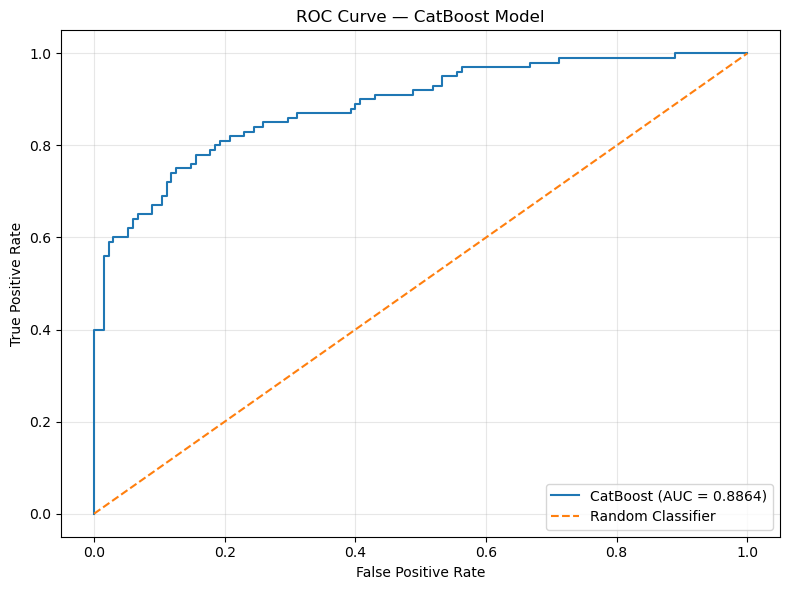

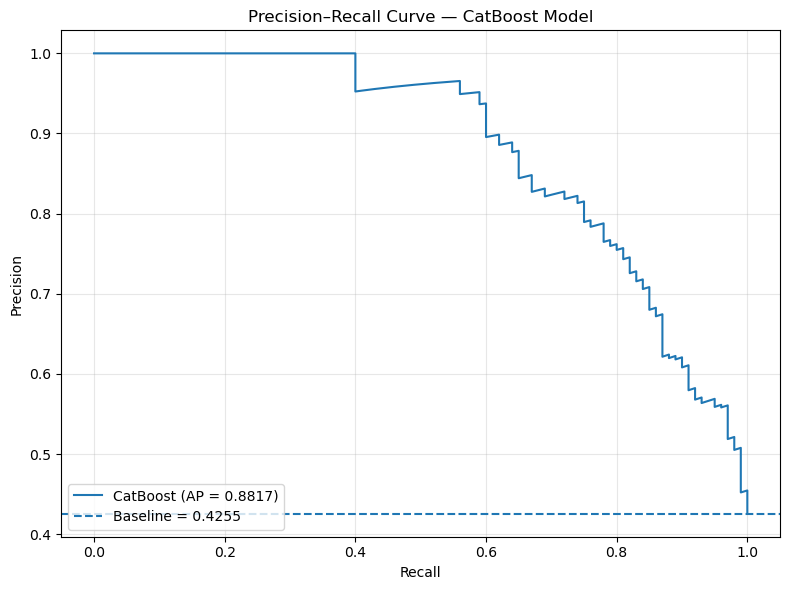

In [23]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

fpr_tree, tpr_tree, roc_thresholds_tree = roc_curve(
    y_test,
    y_prob_tree
)

roc_auc_tree = roc_auc_score(
    y_test,
    y_prob_tree
)
precision_tree, recall_tree, pr_thresholds_tree = precision_recall_curve(
    y_test,
    y_prob_tree
)

average_precision_tree = average_precision_score(
    y_test,
    y_prob_tree
)


print("ROC AND PRECISION-RECALL ANALYSIS")
print("=" * 65)

print(f"ROC-AUC          : {roc_auc_tree:.4f}")
print(f"Average Precision: {average_precision_tree:.4f}")

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"CatBoost (AUC = {roc_auc_tree:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — CatBoost Model"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.savefig(
    "ROC.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(8, 6))

plt.plot(
    recall_tree,
    precision_tree,
    label=f"CatBoost (AP = {average_precision_tree:.4f})"
)

# Baseline prevalence
baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Baseline = {baseline:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision–Recall Curve — CatBoost Model"
)

plt.legend(
    loc="lower left"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.savefig(
    "PR.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

TRAINING CALIBRATED TREE MODELS

Training Platt-scaled CatBoost model...
[OK] Platt scaling completed.

Training isotonic-calibrated CatBoost model...
[OK] Isotonic calibration completed.


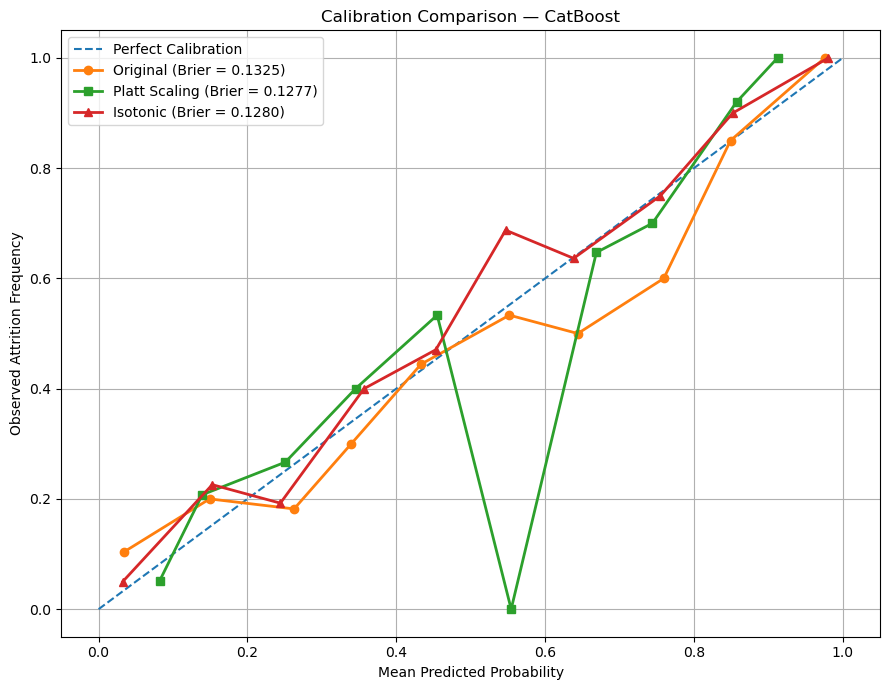


CALIBRATION COMPARISON — CATBOOST
             Method  Brier Score  ROC-AUC
           Original       0.1325   0.8864
      Platt Scaling       0.1277   0.8964
Isotonic Regression       0.1280   0.8927

BEST CALIBRATION METHOD
----------------------------------------------------------------------
Method      : Platt Scaling
Brier Score : 0.1277
ROC-AUC     : 0.8964


In [24]:
from sklearn.calibration import (
CalibratedClassifierCV,
calibration_curve
)

platt_tree_model = CalibratedClassifierCV(
estimator=best_tree_pipeline,
method="sigmoid",
cv=5
)

isotonic_tree_model = CalibratedClassifierCV(
estimator=best_tree_pipeline,
method="isotonic",
cv=5
)

print("TRAINING CALIBRATED TREE MODELS")
print("=" * 65)

print(
f"\nTraining Platt-scaled {best_tree_model_name} model..."
)

platt_tree_model.fit(
X_train,
y_train
)

print("[OK] Platt scaling completed.")

print(
f"\nTraining isotonic-calibrated {best_tree_model_name} model..."
)

isotonic_tree_model.fit(
X_train,
y_train
)

print("[OK] Isotonic calibration completed.")


y_prob_tree_original = (
best_tree_pipeline
.predict_proba(X_test)[:, 1]
)

y_prob_tree_platt = (
platt_tree_model
.predict_proba(X_test)[:, 1]
)

y_prob_tree_isotonic = (
isotonic_tree_model
.predict_proba(X_test)[:, 1]
)


fraction_tree_original, mean_predicted_tree_original = (
calibration_curve(
y_test,
y_prob_tree_original,
n_bins=10,
strategy="uniform"
)
)


fraction_tree_platt, mean_predicted_tree_platt = (
calibration_curve(
y_test,
y_prob_tree_platt,
n_bins=10,
strategy="uniform"
)
)


fraction_tree_isotonic, mean_predicted_tree_isotonic = (
calibration_curve(
y_test,
y_prob_tree_isotonic,
n_bins=10,
strategy="uniform"
)
)

brier_tree_original = brier_score_loss(
y_test,
y_prob_tree_original
)

brier_tree_platt = brier_score_loss(
y_test,
y_prob_tree_platt
)

brier_tree_isotonic = brier_score_loss(
y_test,
y_prob_tree_isotonic
)


roc_tree_original = roc_auc_score(
y_test,
y_prob_tree_original
)

roc_tree_platt = roc_auc_score(
y_test,
y_prob_tree_platt
)

roc_tree_isotonic = roc_auc_score(
y_test,
y_prob_tree_isotonic
)

plt.figure(figsize=(9, 7))

# Perfect calibration

plt.plot(
[0, 1],
[0, 1],
linestyle="--",
label="Perfect Calibration"
)

# Original model

plt.plot(
mean_predicted_tree_original,
fraction_tree_original,
marker="o",
linewidth=2,
label=(
f"Original "
f"(Brier = {brier_tree_original:.4f})"
)
)


plt.plot(
mean_predicted_tree_platt,
fraction_tree_platt,
marker="s",
linewidth=2,
label=(
f"Platt Scaling "
f"(Brier = {brier_tree_platt:.4f})"
)
)


plt.plot(
mean_predicted_tree_isotonic,
fraction_tree_isotonic,
marker="^",
linewidth=2,
label=(
f"Isotonic "
f"(Brier = {brier_tree_isotonic:.4f})"
)
)

plt.xlabel("Mean Predicted Probability")

plt.ylabel("Observed Attrition Frequency")

plt.title(
f"Calibration Comparison — {best_tree_model_name}"
)

plt.legend()

plt.grid(True)

plt.tight_layout()
plt.savefig(
    "calib.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

tree_calibration_results = pd.DataFrame({

"Method": [
    "Original",
    "Platt Scaling",
    "Isotonic Regression"
],

"Brier Score": [
    brier_tree_original,
    brier_tree_platt,
    brier_tree_isotonic
],

"ROC-AUC": [
    roc_tree_original,
    roc_tree_platt,
    roc_tree_isotonic
]


})


print("\n" + "=" * 70)
print(
f"CALIBRATION COMPARISON — "
f"{best_tree_model_name.upper()}"
)
print("=" * 70)

print(
tree_calibration_results
.round(4)
.to_string(index=False)
)

best_tree_calibration = (
tree_calibration_results
.sort_values(
by="Brier Score",
ascending=True
)
.iloc[0]
)

print("\nBEST CALIBRATION METHOD")
print("-" * 70)

print(
"Method      :",
best_tree_calibration["Method"]
)

print(
f"Brier Score : "
f"{best_tree_calibration['Brier Score']:.4f}"
)

print(
f"ROC-AUC     : "
f"{best_tree_calibration['ROC-AUC']:.4f}"
)


In [25]:
error_analysis_tree = pd.DataFrame({
    
    "Actual": y_test.values,
    
    "Predicted": y_pred_tree,
    
    "Predicted_Probability": y_prob_tree,
    
    "Sector": sector_test.values,
    
    "Department": dept_test.values
})

def classify_outcome(actual, predicted):
    
    if actual == 0 and predicted == 0:
        return "True Negative"
    
    elif actual == 1 and predicted == 1:
        return "True Positive"
    
    elif actual == 0 and predicted == 1:
        return "False Positive"
    
    else:
        return "False Negative"


error_analysis_tree["Outcome"] = [
    
    classify_outcome(actual, predicted)
    
    for actual, predicted
    
    in zip(
        error_analysis_tree["Actual"],
        error_analysis_tree["Predicted"]
    )
]

print("ERROR ANALYSIS")
print("=" * 70)

print("\nPrediction outcomes:")

print(
    error_analysis_tree["Outcome"]
    .value_counts()
    .to_string()
)

false_positives_tree = error_analysis_tree[
    error_analysis_tree["Outcome"] == "False Positive"
]

false_negatives_tree = error_analysis_tree[
    error_analysis_tree["Outcome"] == "False Negative"
]


print("\n" + "-" * 70)
print("FALSE POSITIVES")
print("-" * 70)

print("Count:", len(false_positives_tree))

print(
    "Mean predicted probability:",
    round(
        false_positives_tree[
            "Predicted_Probability"
        ].mean(),
        4
    )
)


print("\n" + "-" * 70)
print("FALSE NEGATIVES")
print("-" * 70)

print("Count:", len(false_negatives_tree))

print(
    "Mean predicted probability:",
    round(
        false_negatives_tree[
            "Predicted_Probability"
        ].mean(),
        4
    )
)


sector_error_summary = pd.crosstab(
    
    error_analysis_tree["Sector"],
    
    error_analysis_tree["Outcome"]
)

print("\n" + "=" * 70)
print("ERROR DISTRIBUTION BY SECTOR")
print("=" * 70)

print(
    sector_error_summary
)

department_error_summary = pd.crosstab(
    
    error_analysis_tree["Department"],
    
    error_analysis_tree["Outcome"]
)

print("\n" + "=" * 70)
print("ERROR DISTRIBUTION BY DEPARTMENT")
print("=" * 70)

print(
    department_error_summary
)

error_analysis_tree[
    "Distance_From_Threshold"
] = np.abs(
    error_analysis_tree[
        "Predicted_Probability"
    ] - operating_threshold
)


uncertain_predictions_tree = (
    
    error_analysis_tree
    
    .sort_values(
        "Distance_From_Threshold"
    )
    
    .head(10)
)


print("\n" + "=" * 70)
print("10 MOST UNCERTAIN TEST PREDICTIONS")
print("=" * 70)

print(
    uncertain_predictions_tree[
        [
            "Actual",
            "Predicted",
            "Predicted_Probability",
            "Outcome",
            "Sector",
            "Department",
            "Distance_From_Threshold"
        ]
    ]
    .to_string(
        index=False
    )
)


error_analysis_tree[
    "Is_Error"
] = (
    error_analysis_tree[
        "Actual"
    ]
    !=
    error_analysis_tree[
        "Predicted"
    ]
).astype(int)


sector_error_rate = (
    
    error_analysis_tree
    
    .groupby(
        "Sector"
    )
    
    .agg(
        Total=("Is_Error", "count"),
        Errors=("Is_Error", "sum"),
        Error_Rate=("Is_Error", "mean")
    )
    
    .sort_values(
        "Error_Rate",
        ascending=False
    )
)


print("\n" + "=" * 70)
print("ERROR RATE BY SECTOR")
print("=" * 70)

print(
    sector_error_rate.to_string()
)

department_error_rate = (
    
    error_analysis_tree
    
    .groupby(
        "Department"
    )
    
    .agg(
        Total=("Is_Error", "count"),
        Errors=("Is_Error", "sum"),
        Error_Rate=("Is_Error", "mean")
    )
    
    .sort_values(
        "Error_Rate",
        ascending=False
    )
)


print("\n" + "=" * 70)
print("ERROR RATE BY DEPARTMENT")
print("=" * 70)

print(
    department_error_rate.to_string()
)


print("\n[OK] Error analysis completed.")

ERROR ANALYSIS

Prediction outcomes:
Outcome
True Negative     114
True Positive      77
False Negative     23
False Positive     21

----------------------------------------------------------------------
FALSE POSITIVES
----------------------------------------------------------------------
Count: 21
Mean predicted probability: 0.6648

----------------------------------------------------------------------
FALSE NEGATIVES
----------------------------------------------------------------------
Count: 23
Mean predicted probability: 0.2

ERROR DISTRIBUTION BY SECTOR
Outcome    False Negative  False Positive  True Negative  True Positive
Sector                                                                 
Education               7               3             35              8
Financial               1               4             18             10
Food                    0               4              7              6
Medical                11               6             29             21


In [26]:
import shap
fitted_catboost = best_tree_pipeline.named_steps["model"]

print("INITIALIZING SHAP EXPLAINER")
print("=" * 70)

explainer_tree = shap.TreeExplainer(
    fitted_catboost
)

shap_values_tree = explainer_tree.shap_values(
    X_test
)

if isinstance(shap_values_tree, list):
    
    shap_values_positive_tree = shap_values_tree[1]

else:
    
    shap_values_positive_tree = shap_values_tree

mean_abs_shap_tree = np.abs(
    shap_values_positive_tree
).mean(
    axis=0
)


shap_importance_tree = pd.DataFrame({

    "Feature": X_test.columns,

    "Mean_Absolute_SHAP":
        mean_abs_shap_tree

})

shap_importance_tree = (
    
    shap_importance_tree
    
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 70)
print("TOP 20 FEATURES — MEAN ABSOLUTE SHAP VALUE")
print("=" * 70)

print(
    shap_importance_tree
    .head(20)
    .to_string(
        index=False
    )
)

shap_importance_tree[
    "Relative_Importance_Percent"
] = (
    
    shap_importance_tree[
        "Mean_Absolute_SHAP"
    ]
    
    /
    
    shap_importance_tree[
        "Mean_Absolute_SHAP"
    ].sum()
    
    * 100
)


print("\n" + "=" * 70)
print("TOP 20 FEATURES — RELATIVE SHAP IMPORTANCE")
print("=" * 70)

print(
    shap_importance_tree[
        [
            "Feature",
            "Mean_Absolute_SHAP",
            "Relative_Importance_Percent"
        ]
    ]
    
    .head(20)
    
    .to_string(
        index=False
    )
)


top_features_tree = (
    
    shap_importance_tree
    
    .head(20)
    
    .copy()
)


print("\n[OK] Quantitative SHAP feature importance completed.")

INITIALIZING SHAP EXPLAINER

TOP 20 FEATURES — MEAN ABSOLUTE SHAP VALUE
                                  Feature  Mean_Absolute_SHAP
                         Years_Experience            1.333142
        Years_experience_lastorganization            1.240593
                                 JobTitle            0.934302
                        Job_Opportunities            0.801734
                     Emotional_Commitment            0.339604
                            Job_Stability            0.279350
Training_programs_During_last_three_years            0.269907
                   Get_Deserved_Promotion            0.165439
                 Psychological_Exhaustion            0.160897
                               Allowances            0.156360
                              Job_Support            0.125242
                         Payment_Overtime            0.119563
                                   Sector            0.117779
                           Job_Engagement            0.11655

SHAP SUMMARY PLOT


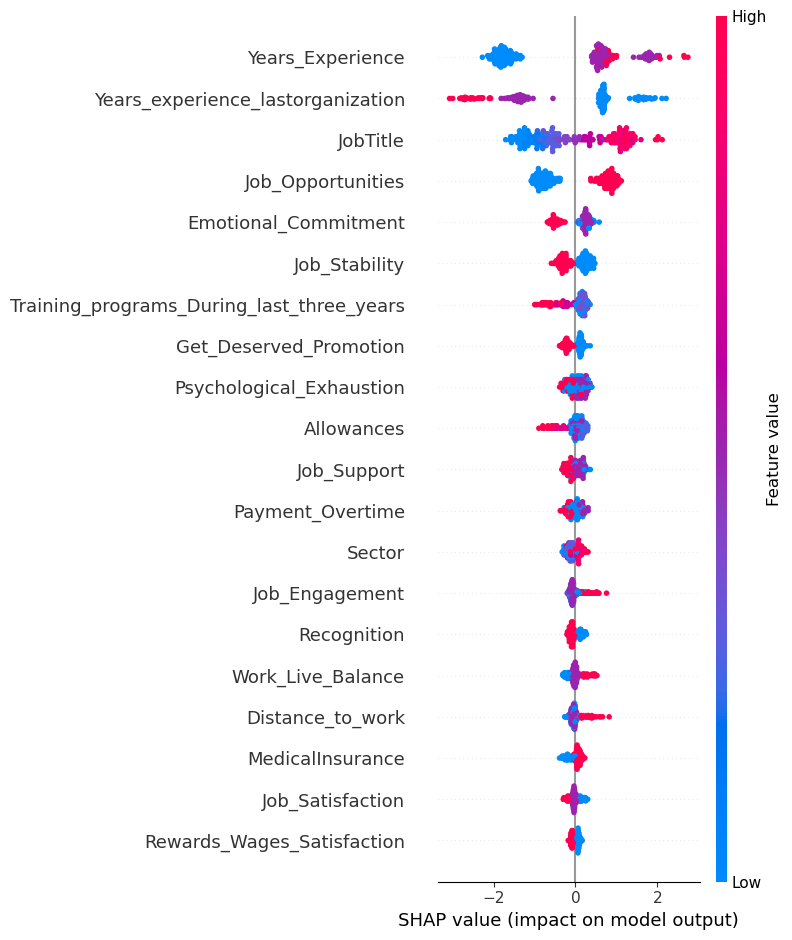

In [27]:
print("SHAP SUMMARY PLOT")
print("=" * 70)

shap.summary_plot(
    
    shap_values_positive_tree,
    
    X_test,
    
    max_display=20,
    
    show=False
)
# Adjust layout
plt.tight_layout()

# Save at 600 DPI
plt.savefig(
    "SHAP_Summary_Plot_Tree_Model.png",
    dpi=600,
    bbox_inches="tight"
)

# Display plot
plt.show()

# Close figure
plt.close()


In [28]:
from scipy.stats import spearmanr

top_n = 10

top_features_for_direction = (
    shap_importance_tree
    .head(top_n)["Feature"]
    .tolist()
)

direction_results = []

for feature in top_features_for_direction:

    feature_index = list(X_test.columns).index(feature)

    feature_values = X_test[feature].values

    feature_shap_values = (
        shap_values_positive_tree[:, feature_index]
    )

    correlation, p_value = spearmanr(
        feature_values,
        feature_shap_values
    )

    direction = (
        "Higher values tend to increase attrition prediction"
        if correlation > 0
        else
        "Higher values tend to decrease attrition prediction"
    )

    direction_results.append({

        "Feature": feature,

        "Mean_Absolute_SHAP":
            shap_importance_tree.loc[
                shap_importance_tree["Feature"] == feature,
                "Mean_Absolute_SHAP"
            ].iloc[0],

        "Spearman_Correlation":
            correlation,

        "P_Value":
            p_value,

        "General_Direction":
            direction
    })


shap_direction_tree = pd.DataFrame(
    direction_results
)



shap_direction_display = (
    shap_direction_tree
    .copy()
)

shap_direction_display[
    "Mean_Absolute_SHAP"
] = (
    shap_direction_display[
        "Mean_Absolute_SHAP"
    ].round(4)
)

shap_direction_display[
    "Spearman_Correlation"
] = (
    shap_direction_display[
        "Spearman_Correlation"
    ].round(4)
)

shap_direction_display[
    "P_Value"
] = (
    shap_direction_display[
        "P_Value"
    ].round(6)
)


print("QUANTITATIVE SHAP DIRECTIONAL ANALYSIS")
print("=" * 100)

print(
    shap_direction_display.to_string(
        index=False
    )
)


print("\nINTERPRETATION GUIDE")
print("-" * 100)
print("Positive correlation → Higher feature values generally increase predicted attrition.")
print("Negative correlation → Higher feature values generally decrease predicted attrition.")
print("Correlation near zero → Relationship may be non-linear or more complex.")

QUANTITATIVE SHAP DIRECTIONAL ANALYSIS
                                  Feature  Mean_Absolute_SHAP  Spearman_Correlation  P_Value                                   General_Direction
                         Years_Experience              1.3331                0.8598 0.000000 Higher values tend to increase attrition prediction
        Years_experience_lastorganization              1.2406               -0.8802 0.000000 Higher values tend to decrease attrition prediction
                                 JobTitle              0.9343                0.9628 0.000000 Higher values tend to increase attrition prediction
                        Job_Opportunities              0.8017                0.8658 0.000000 Higher values tend to increase attrition prediction
                     Emotional_Commitment              0.3396               -0.7436 0.000000 Higher values tend to decrease attrition prediction
                            Job_Stability              0.2793               -0.8651 0.00000

In [29]:
MIN_SUBGROUP_SIZE = 20
MIN_CLASS_SIZE = 5
N_BOOTSTRAPS = 1000


def safe_roc_auc(y_true, y_probability):

    if len(np.unique(y_true)) < 2:
        return np.nan

    return roc_auc_score(
        y_true,
        y_probability
    )


def bootstrap_metric_ci(
    y_true,
    y_pred,
    y_prob,
    metric_name,
    n_bootstraps=N_BOOTSTRAPS,
    random_state=SEED
):

    rng = np.random.RandomState(random_state)

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)

    bootstrap_scores = []

    n = len(y_true)

    for _ in range(n_bootstraps):

        # Sample observations with replacement
        indices = rng.choice(
            np.arange(n),
            size=n,
            replace=True
        )

        y_true_boot = y_true[indices]
        y_pred_boot = y_pred[indices]
        y_prob_boot = y_prob[indices]


        # Skip bootstrap samples with only one class
        if len(np.unique(y_true_boot)) < 2:
            continue



        if metric_name == "Accuracy":

            score = accuracy_score(
                y_true_boot,
                y_pred_boot
            )


        elif metric_name == "Precision":

            score = precision_score(
                y_true_boot,
                y_pred_boot,
                zero_division=0
            )


        elif metric_name == "Recall":

            score = recall_score(
                y_true_boot,
                y_pred_boot,
                zero_division=0
            )


        elif metric_name == "F1 Score":

            score = f1_score(
                y_true_boot,
                y_pred_boot,
                zero_division=0
            )


        elif metric_name == "ROC AUC":

            score = roc_auc_score(
                y_true_boot,
                y_prob_boot
            )


        bootstrap_scores.append(score)



    if len(bootstrap_scores) == 0:
        return np.nan, np.nan

    lower_ci = np.percentile(
        bootstrap_scores,
        2.5
    )

    upper_ci = np.percentile(
        bootstrap_scores,
        97.5
    )

    return lower_ci, upper_ci


def subgroup_performance_analysis(
    y_true,
    y_predicted,
    y_probability,
    subgroup_labels,
    min_subgroup_size=MIN_SUBGROUP_SIZE,
    min_class_size=MIN_CLASS_SIZE
):

    results = []


    # Ensure index alignment
    subgroup_labels = pd.Series(
        subgroup_labels,
        index=y_true.index
    )


    for subgroup in sorted(subgroup_labels.unique()):

        mask = (
            subgroup_labels == subgroup
        )

        y_true_group = y_true[mask]
        y_pred_group = np.asarray(y_predicted)[mask]
        y_prob_group = np.asarray(y_probability)[mask]


        sample_size = len(
            y_true_group
        )

        attrition_cases = int(
            np.sum(y_true_group)
        )

        non_attrition_cases = int(
            sample_size - attrition_cases
        )


        sufficient_sample_size = (
            sample_size >= min_subgroup_size
        )

        sufficient_class_size = (
            attrition_cases >= min_class_size
            and
            non_attrition_cases >= min_class_size
        )

        sufficient_data = (
            sufficient_sample_size
            and
            sufficient_class_size
        )


        if not sufficient_data:

            results.append({

                "Group": subgroup,

                "Sample Size":
                    sample_size,

                "Attrition Cases":
                    attrition_cases,

                "Non-Attrition Cases":
                    non_attrition_cases,

                "Status":
                    "Insufficient subgroup size",

                "Accuracy":
                    np.nan,

                "Accuracy 95% CI":
                    "N/A",

                "Precision":
                    np.nan,

                "Precision 95% CI":
                    "N/A",

                "Recall":
                    np.nan,

                "Recall 95% CI":
                    "N/A",

                "F1 Score":
                    np.nan,

                "F1 Score 95% CI":
                    "N/A",

                "ROC AUC":
                    np.nan,

                "ROC AUC 95% CI":
                    "N/A"
            })

            continue

        accuracy = accuracy_score(
            y_true_group,
            y_pred_group
        )

        precision = precision_score(
            y_true_group,
            y_pred_group,
            zero_division=0
        )

        recall = recall_score(
            y_true_group,
            y_pred_group,
            zero_division=0
        )

        f1 = f1_score(
            y_true_group,
            y_pred_group,
            zero_division=0
        )

        roc_auc = safe_roc_auc(
            y_true_group,
            y_prob_group
        )


        accuracy_ci = bootstrap_metric_ci(
            y_true_group,
            y_pred_group,
            y_prob_group,
            "Accuracy"
        )

        precision_ci = bootstrap_metric_ci(
            y_true_group,
            y_pred_group,
            y_prob_group,
            "Precision"
        )

        recall_ci = bootstrap_metric_ci(
            y_true_group,
            y_pred_group,
            y_prob_group,
            "Recall"
        )

        f1_ci = bootstrap_metric_ci(
            y_true_group,
            y_pred_group,
            y_prob_group,
            "F1 Score"
        )

        roc_auc_ci = bootstrap_metric_ci(
            y_true_group,
            y_pred_group,
            y_prob_group,
            "ROC AUC"
        )



        results.append({

            "Group": subgroup,

            "Sample Size":
                sample_size,

            "Attrition Cases":
                attrition_cases,

            "Non-Attrition Cases":
                non_attrition_cases,

            "Status":
                "Sufficient",

            "Accuracy":
                accuracy,

            "Accuracy 95% CI":
                f"[{accuracy_ci[0]:.3f}, "
                f"{accuracy_ci[1]:.3f}]",

            "Precision":
                precision,

            "Precision 95% CI":
                f"[{precision_ci[0]:.3f}, "
                f"{precision_ci[1]:.3f}]",

            "Recall":
                recall,

            "Recall 95% CI":
                f"[{recall_ci[0]:.3f}, "
                f"{recall_ci[1]:.3f}]",

            "F1 Score":
                f1,

            "F1 Score 95% CI":
                f"[{f1_ci[0]:.3f}, "
                f"{f1_ci[1]:.3f}]",

            "ROC AUC":
                roc_auc,

            "ROC AUC 95% CI":
                f"[{roc_auc_ci[0]:.3f}, "
                f"{roc_auc_ci[1]:.3f}]"
        })


    return pd.DataFrame(
        results
    )

In [30]:
tree_sector_performance = subgroup_performance_analysis(
    y_true=y_test,
    y_predicted=y_pred_tree,
    y_probability=y_prob_tree,
    subgroup_labels=sector_test
)

tree_department_performance = subgroup_performance_analysis(
    y_true=y_test,
    y_predicted=y_pred_tree,
    y_probability=y_prob_tree,
    subgroup_labels=dept_test
)

In [31]:
sector_distribution = pd.DataFrame({

    "Sector":
        df["Sector_Label"].value_counts().index,

    "Sample Size":
        df["Sector_Label"].value_counts().values
})


department_distribution = pd.DataFrame({

    "Department":
        df["Dept_Label"].value_counts().index,

    "Sample Size":
        df["Dept_Label"].value_counts().values
})


print("SECTOR DISTRIBUTION")
print("=" * 65)

print(
    sector_distribution
    .sort_values("Sample Size", ascending=False)
    .to_string(index=False)
)


print("\nDEPARTMENT DISTRIBUTION")
print("=" * 65)

print(
    department_distribution
    .sort_values("Sample Size", ascending=False)
    .to_string(index=False)
)

SECTOR DISTRIBUTION
   Sector  Sample Size
    Other          343
  Medical          298
Education          269
Financial          151
     Food          113

DEPARTMENT DISTRIBUTION
      Department  Sample Size
           Other          219
  Administration          190
        Teaching          184
 Patient Affairs          145
Customer Service          142
           Sales          134
       Processes           97
      Accounting           63


In [32]:


print("\n" + "=" * 120)
print(
    f"TREE MODEL — SECTOR-WISE PERFORMANCE "
    f"({best_tree_model_name})"
)
print("=" * 120)

print(
    tree_sector_performance
    .round({
        "Accuracy": 4,
        "Precision": 4,
        "Recall": 4,
        "F1 Score": 4,
        "ROC AUC": 4
    })
    .to_string(index=False)
)


print("\n" + "=" * 120)
print(
    f"TREE MODEL — DEPARTMENT-WISE PERFORMANCE "
    f"({best_tree_model_name})"
)
print("=" * 120)

print(
    tree_department_performance
    .round({
        "Accuracy": 4,
        "Precision": 4,
        "Recall": 4,
        "F1 Score": 4,
        "ROC AUC": 4
    })
    .to_string(index=False)
)


TREE MODEL — SECTOR-WISE PERFORMANCE (CatBoost)
    Group  Sample Size  Attrition Cases  Non-Attrition Cases                     Status  Accuracy Accuracy 95% CI  Precision Precision 95% CI  Recall  Recall 95% CI  F1 Score F1 Score 95% CI  ROC AUC ROC AUC 95% CI
Education           53               15                   38                 Sufficient    0.8113  [0.698, 0.906]     0.7273   [0.444, 1.000]  0.5333 [0.278, 0.800]    0.6154  [0.364, 0.811]   0.7930 [0.638, 0.926]
Financial           33               11                   22                 Sufficient    0.8485  [0.697, 0.970]     0.7143   [0.462, 0.933]  0.9091 [0.700, 1.000]    0.8000  [0.571, 0.950]   0.9628 [0.892, 1.000]
     Food           17                6                   11 Insufficient subgroup size       NaN             N/A        NaN              N/A     NaN            N/A       NaN             N/A      NaN            N/A
  Medical           67               32                   35                 Sufficient    

In [33]:
import catboost
import xgboost
import lightgbm

print("CatBoost version:", catboost.__version__)
print("XGBoost version:", xgboost.__version__)
print("LightGBM version:", lightgbm.__version__)

CatBoost version: 1.2.10
XGBoost version: 3.4.0
LightGBM version: 4.6.0


In [34]:
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import seaborn
import scipy

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("Seaborn version:", seaborn.__version__)
print("SciPy version:", scipy.__version__)

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
NumPy version: 2.3.5
Pandas version: 2.3.3
Scikit-learn version: 1.7.2
Matplotlib version: 3.10.6
Seaborn version: 0.13.2
SciPy version: 1.16.3
